# Task 1: Diagnostic Enhancement of Chest X-Rays
Sample image: `data/chest_xray.png` (PNEUMONIA_10.png from the COVID19+PNEUMONIA+NORMAL Chest X-Ray dataset)

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## 1. Load and Display

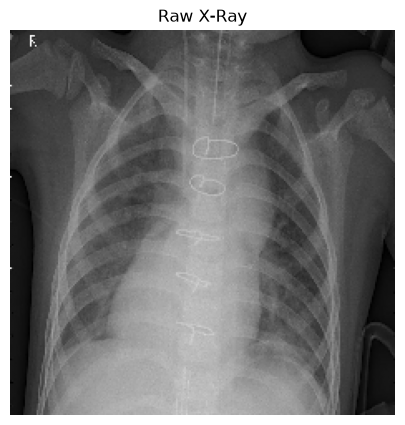

Shape: (232, 232)
Min: 0 Max: 255 Mean: 98.57


In [2]:
# Read the X-ray as a single channel (grayscale) image
gray = cv2.imread("data/chest_xray.png", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 5))
plt.imshow(gray, cmap="gray")
plt.title("Raw X-Ray")
plt.axis("off")
plt.show()

print("Shape:", gray.shape)
print("Min:", gray.min(), "Max:", gray.max(), "Mean:", round(gray.mean(), 2))

## 2. Contrast Enhancement (Histogram Equalization)
Equalization spreads the pixel values over the full 0-255 range, so the lung area and ribs get more contrast.

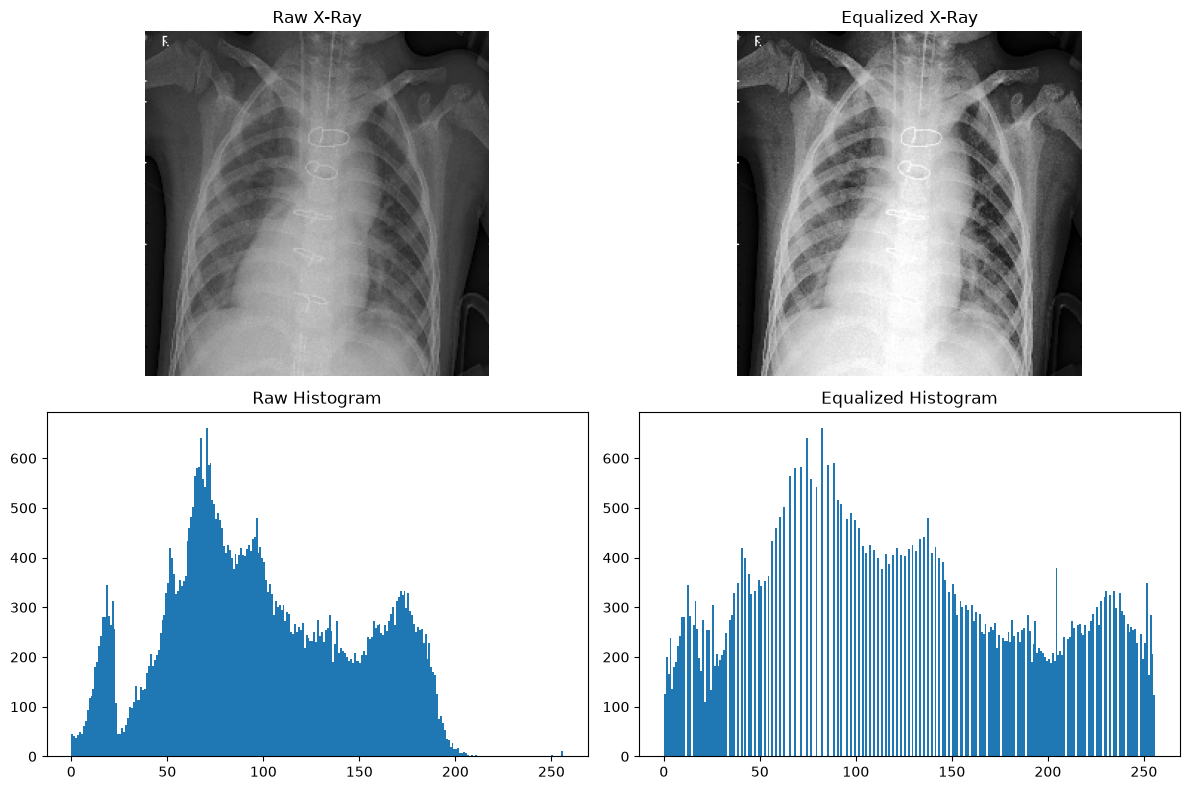

In [3]:
equalized = cv2.equalizeHist(gray)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Raw X-Ray")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized X-Ray")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.hist(gray.ravel(), bins=256, range=[0, 256])
plt.title("Raw Histogram")

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), bins=256, range=[0, 256])
plt.title("Equalized Histogram")

plt.tight_layout()
plt.savefig("output/1_equalization.png")
plt.show()

**Observation:** the raw histogram is packed in a narrow range, after equalization it covers the whole range.
The lung structures and rib edges are now much easier to see.

## 3. Color Mapping (COLORMAP_JET)
The eye can tell colors apart better than gray levels, so small intensity changes (like fluid boundaries) show up as a change in color.

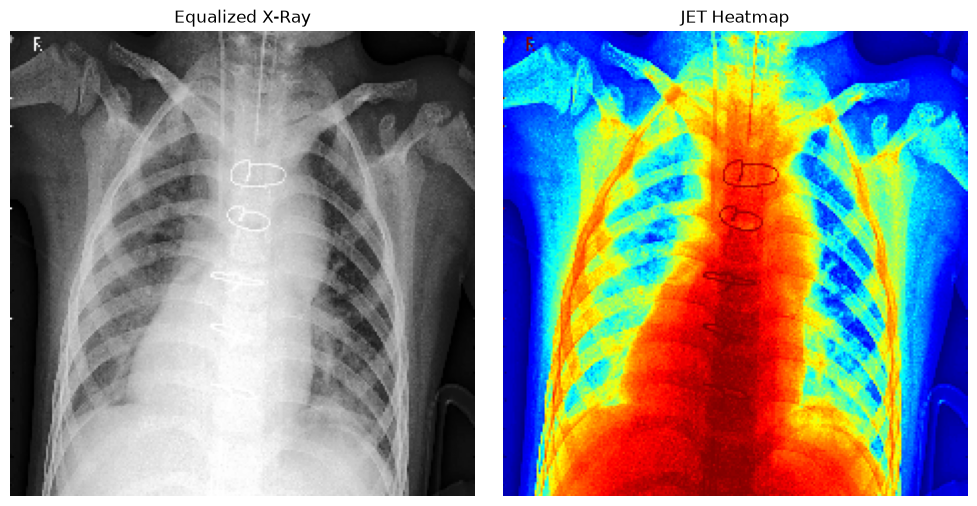

In [4]:
heatmap = cv2.applyColorMap(equalized, cv2.COLORMAP_JET)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized X-Ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB))
plt.title("JET Heatmap")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/2_heatmap.png")
plt.show()

## 4. Color Balance (Gray World)
Each channel is scaled so its average becomes equal to the overall average. This evens out the three color channels so no single color dominates.

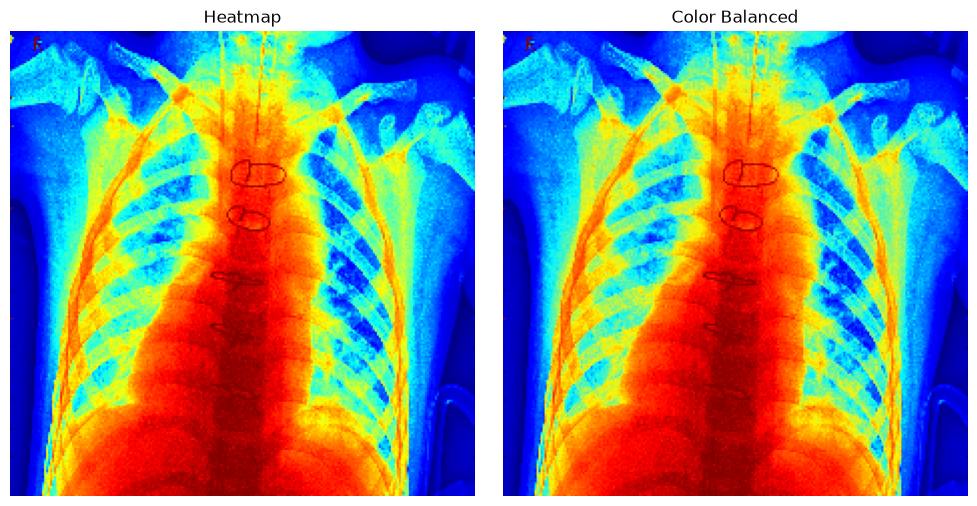

Channel means before (B, G, R): [119.0, 127.7, 120.3]
Channel means after  (B, G, R): [120.3, 122.0, 121.0]


In [5]:
b, g, r = cv2.split(heatmap.astype(np.float32))
avg = (b.mean() + g.mean() + r.mean()) / 3

b = b * (avg / b.mean())
g = g * (avg / g.mean())
r = r * (avg / r.mean())

balanced = cv2.merge([b, g, r])
balanced = np.clip(balanced, 0, 255).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB))
plt.title("Heatmap")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(balanced, cv2.COLOR_BGR2RGB))
plt.title("Color Balanced")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/3_color_balance.png")
plt.show()

print("Channel means before (B, G, R):", [round(m, 1) for m in cv2.mean(heatmap)[:3]])
print("Channel means after  (B, G, R):", [round(m, 1) for m in cv2.mean(balanced)[:3]])

## 5. Color Filtering (Thresholding)
Dense tissue (bone / dense fluid) is the brightest part of the image, so we keep only pixels above 200.

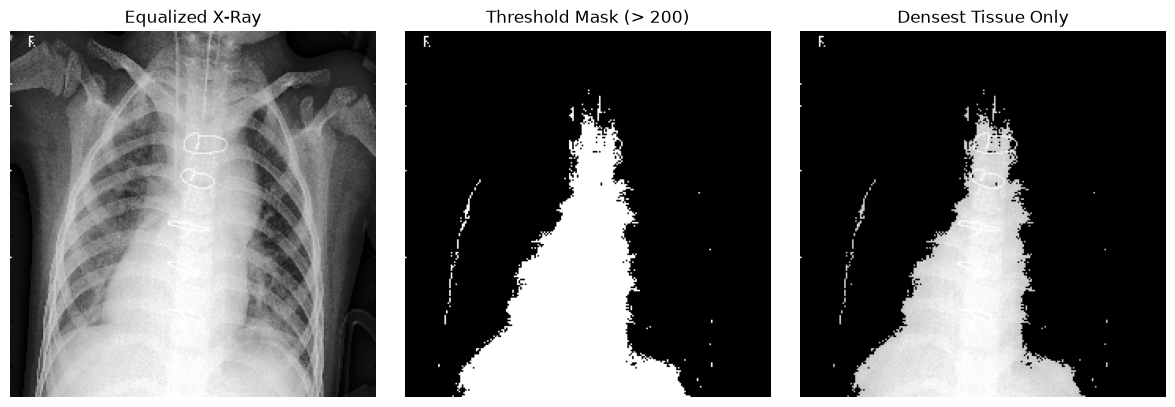

In [6]:
_, mask = cv2.threshold(equalized, 200, 255, cv2.THRESH_BINARY)
dense = cv2.bitwise_and(equalized, equalized, mask=mask)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized X-Ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Threshold Mask (> 200)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dense, cmap="gray")
plt.title("Densest Tissue Only")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/4_threshold.png")
plt.show()

## 6. Logarithmic Transformation
`s = c * log(1 + r)`, with `c = 255 / log(1 + 255)`. Dark values are stretched a lot, bright values only a little, so faint edges in the dark area appear.

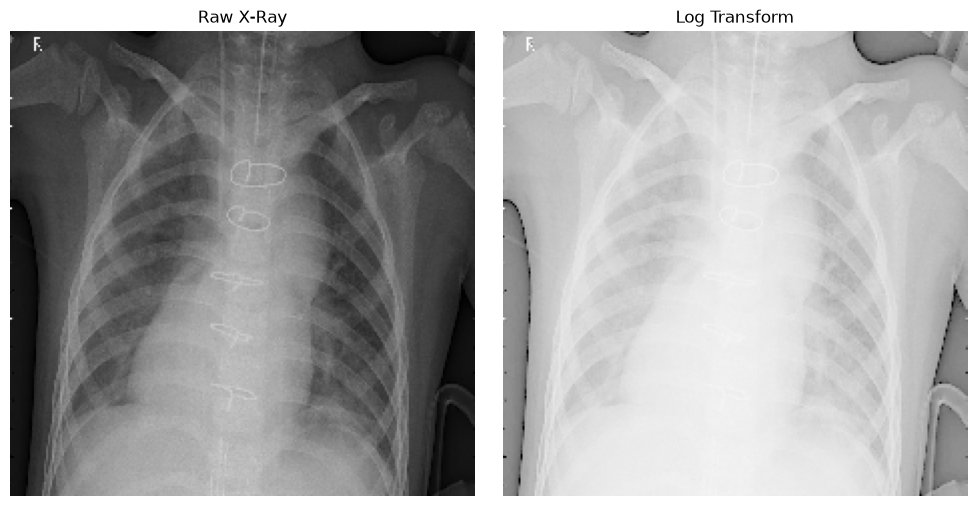

In [7]:
c = 255 / np.log(1 + 255)
log_image = c * np.log(1 + gray.astype(np.float32))
log_image = np.uint8(log_image)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Raw X-Ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(log_image, cmap="gray")
plt.title("Log Transform")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/5_log.png")
plt.show()

## 7. Power-Law (Gamma) Transformation
`s = 255 * (r / 255) ^ gamma` with `gamma = 0.5` (< 1). Midtones get brighter, so the soft lung tissue is clearer and the bones look less harsh.

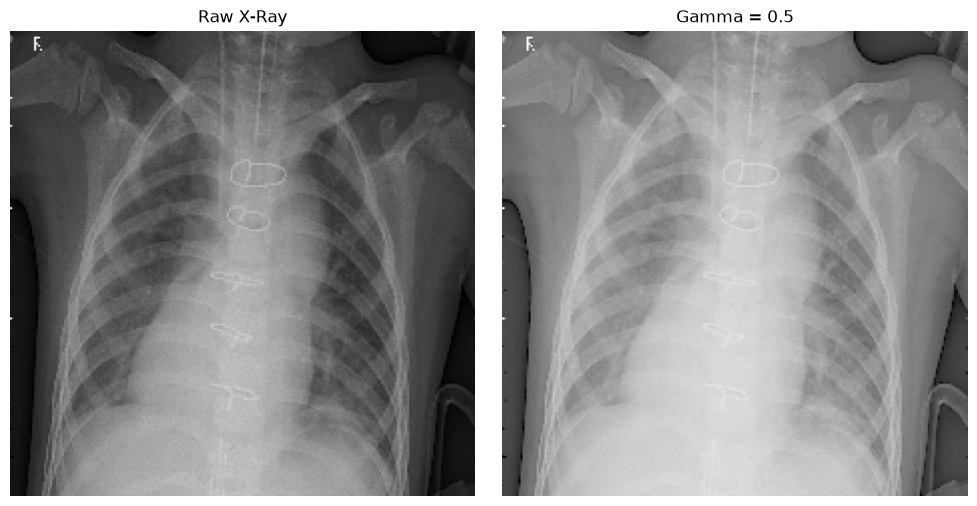

In [8]:
gamma = 0.5
gamma_image = 255 * (gray / 255) ** gamma
gamma_image = np.uint8(gamma_image)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Raw X-Ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gamma_image, cmap="gray")
plt.title("Gamma = 0.5")
plt.axis("off")

plt.tight_layout()
plt.savefig("output/6_gamma.png")
plt.show()

## Summary

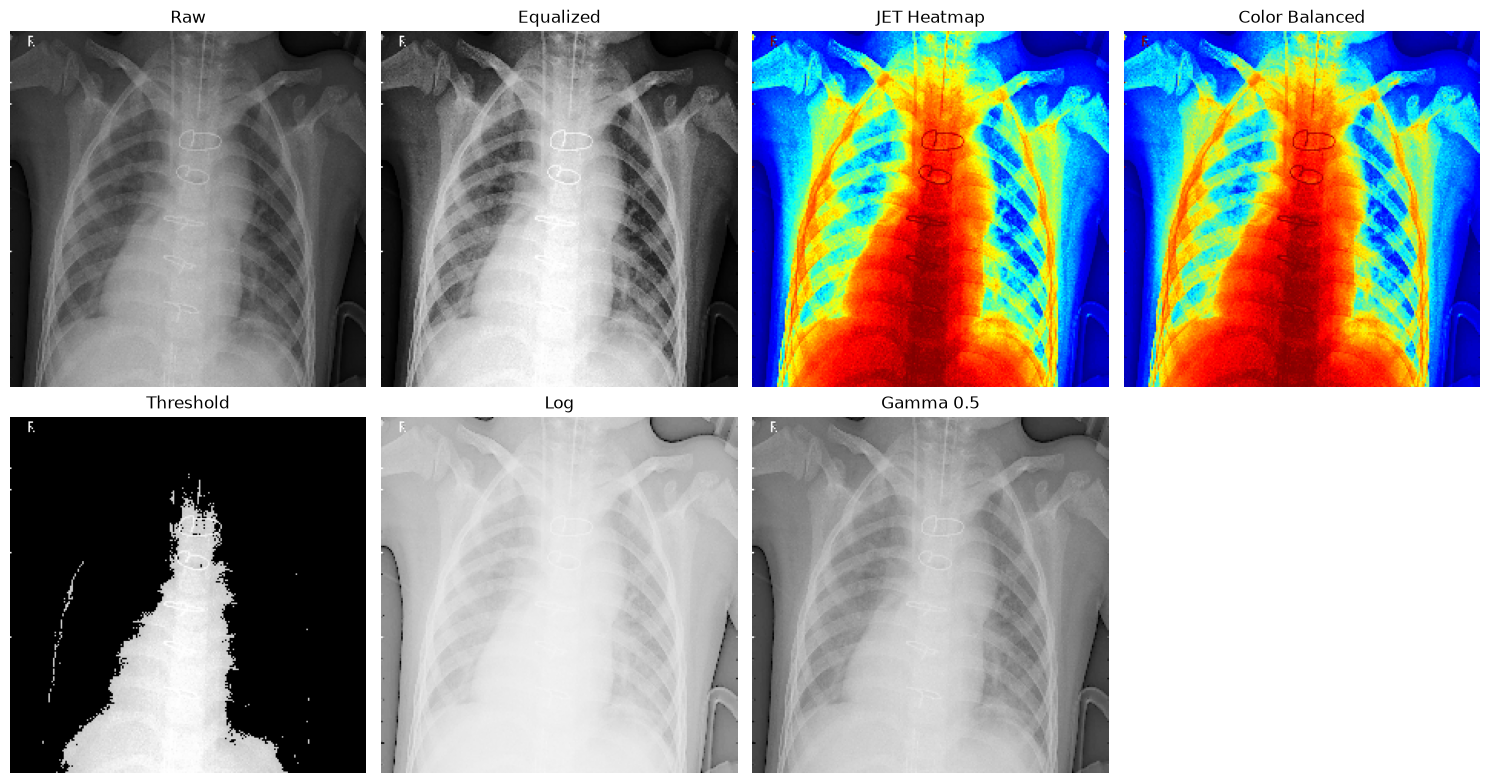

In [9]:
plt.figure(figsize=(15, 8))

images = [gray, equalized, heatmap, balanced, dense, log_image, gamma_image]
titles = ["Raw", "Equalized", "JET Heatmap", "Color Balanced", "Threshold", "Log", "Gamma 0.5"]

for i in range(len(images)):
    plt.subplot(2, 4, i + 1)
    if len(images[i].shape) == 3:
        plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.savefig("output/summary.png")
plt.show()